In [14]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

# a notebook in notebooks/ runs from that folder, hence "../data"
path = "../data/realized_variance_stocks_20261030/realized_variance_stocks_20261030.csv"
stocks = pd.read_csv(path, parse_dates=["date"])
stocks.head()

,date,symbol,asset_type,volume,trades,open_price,close_price,high_price,low_price,pr,...,medrv5,medrv5_ss,minrv1,minrv5,minrv5_ss,rk,rq1,rq5,rq5_ss,index
0,2015-01-02,AAPL,stocks,52510449,286295,111.3973,109.240,111.47,107.350,0.000512,...,0.000307,0.000291,0.000269,0.000365,0.000310,0.000291,1.636997e-07,9.045224e-07,5.234818e-07,"DOW30, S&P100"
1,2015-01-05,AAPL,stocks,60727778,316713,108.2914,106.380,108.65,105.410,0.000331,...,0.000342,0.000221,0.000277,0.000365,0.000261,0.000220,1.362068e-07,2.405967e-07,1.006578e-07,"DOW30, S&P100"
2,2015-01-06,AAPL,stocks,64865433,362762,106.4644,106.300,107.42,104.630,0.000250,...,0.000525,0.000416,0.000364,0.000576,0.000410,0.000341,2.224424e-07,1.825222e-07,1.929761e-07,"DOW30, S&P100"
3,2015-01-07,AAPL,stocks,39052235,220326,107.1898,107.825,108.20,106.695,0.000071,...,0.000186,0.000155,0.000201,0.000188,0.000156,0.000183,7.237007e-08,2.564956e-08,3.986406e-08,"DOW30, S&P100"
4,2015-01-08,AAPL,stocks,57390801,302187,109.3600,111.940,112.15,108.700,0.000352,...,0.000137,0.000120,0.000131,0.000134,0.000129,0.000136,8.016973e-08,1.968634e-08,3.549955e-08,"DOW30, S&P100"


In [15]:
df = stocks.sort_values(["symbol", "date"]).copy()


In [16]:
bad_days = [("2023-01-24", "MCD"), ("2023-01-24", "NKE"), ("2023-01-24", "V"),
            ("2023-01-24", "WMT"), ("2023-01-24", "XOM"), ("2016-09-27", "PG")]

for d, s in bad_days:
    df.loc[(df["date"] == d) & (df["symbol"] == s), "rv5"] = np.nan

In [17]:
df["y"] = np.log(df["rv5"])
df['x_week'] = df.groupby('symbol')['y'].transform(lambda s: s.rolling(5).mean())
df

,date,symbol,asset_type,volume,trades,open_price,close_price,high_price,low_price,pr,...,minrv1,minrv5,minrv5_ss,rk,rq1,rq5,rq5_ss,index,y,x_week
0,2015-01-02,AAPL,stocks,52510449,286295,111.3973,109.240,111.4700,107.3500,0.000512,...,0.000269,0.000365,0.000310,0.000291,1.636997e-07,9.045224e-07,5.234818e-07,"DOW30, S&P100",-7.770309,NaN
1,2015-01-05,AAPL,stocks,60727778,316713,108.2914,106.380,108.6500,105.4100,0.000331,...,0.000277,0.000365,0.000261,0.000220,1.362068e-07,2.405967e-07,1.006578e-07,"DOW30, S&P100",-8.028547,NaN
2,2015-01-06,AAPL,stocks,64865433,362762,106.4644,106.300,107.4200,104.6300,0.000250,...,0.000364,0.000576,0.000410,0.000341,2.224424e-07,1.825222e-07,1.929761e-07,"DOW30, S&P100",-7.653719,NaN
3,2015-01-07,AAPL,stocks,39052235,220326,107.1898,107.825,108.2000,106.6950,0.000071,...,0.000201,0.000188,0.000156,0.000183,7.237007e-08,2.564956e-08,3.986406e-08,"DOW30, S&P100",-8.764940,NaN
4,2015-01-08,AAPL,stocks,57390801,302187,109.3600,111.940,112.1500,108.7000,0.000352,...,0.000131,0.000134,0.000129,0.000136,8.016973e-08,1.968634e-08,3.549955e-08,"DOW30, S&P100",-8.923221,-8.228147
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
118995,2026-10-26,XOM,stocks,10658330,157582,181.8600,184.540,184.7615,181.5200,0.000113,...,0.000095,0.000085,0.000087,0.000092,2.109079e-08,2.014583e-08,2.874983e-08,S&P100,-9.233079,-8.792040
118996,2026-10-27,XOM,stocks,13890404,176666,183.6300,179.920,184.8900,179.7400,0.000288,...,0.000171,0.000100,0.000138,0.000136,9.997153e-08,2.223094e-08,2.299576e-08,S&P100,-9.014519,-8.899991
118997,2026-10-28,XOM,stocks,11674520,169865,180.5850,182.020,183.6500,179.9000,0.000154,...,0.000168,0.000130,0.000104,0.000131,1.535588e-07,3.861827e-08,2.477020e-08,S&P100,-8.748838,-8.871302
118998,2026-10-29,XOM,stocks,10791337,141263,183.7650,183.290,184.4000,180.9400,0.000129,...,0.000131,0.000070,0.000111,0.000152,3.413666e-07,8.253299e-08,5.090409e-08,S&P100,-8.690082,-8.901751


In [18]:
df['x_day'] = df['y']
df['x_month'] = df.groupby('symbol')['y'].transform(lambda s: s.rolling(22).mean())
df["target"] = df.groupby('symbol')["y"].shift(-1)


In [19]:
# All these are the last element in each symbol and target should be NaN since we moved up by one with the shift
df.groupby("symbol").tail(1)[["symbol", "date", "target"]]


,symbol,date,target
2974,AAPL,2026-10-30,NaN
5949,ADBE,2026-10-30,NaN
8924,AMD,2026-10-30,NaN
11899,AMGN,2026-10-30,NaN
14874,AMZN,2026-10-30,NaN
17849,AXP,2026-10-30,NaN
20824,BA,2026-10-30,NaN
23799,CAT,2026-10-30,NaN
26774,CRM,2026-10-30,NaN
29749,CSCO,2026-10-30,NaN


In [20]:
df = df.dropna(subset=["x_day", "x_week", "x_month", "target"])
df

,date,symbol,asset_type,volume,trades,open_price,close_price,high_price,low_price,pr,...,rk,rq1,rq5,rq5_ss,index,y,x_week,x_day,x_month,target
21,2015-02-03,AAPL,stocks,50056136,246526,118.4600,118.60,119.0900,117.610,0.000056,...,0.000121,7.353158e-08,1.036997e-08,1.088724e-08,"DOW30, S&P100",-9.257019,-8.471831,-9.257019,-8.409604,-8.868904
22,2015-02-04,AAPL,stocks,69144055,321263,118.5033,119.49,120.5100,118.309,0.000123,...,0.000138,6.027852e-08,2.752340e-08,2.946939e-08,"DOW30, S&P100",-8.868904,-8.677110,-8.868904,-8.459541,-9.940664
23,2015-02-05,AAPL,stocks,41004682,207132,120.0200,119.83,120.2300,119.250,0.000024,...,0.000062,1.159512e-08,2.045874e-09,3.279185e-09,"DOW30, S&P100",-9.940664,-8.969454,-9.940664,-8.546455,-9.431916
24,2015-02-06,AAPL,stocks,42805295,231982,120.0500,118.87,120.2500,118.450,0.000082,...,0.000094,1.732330e-08,9.479759e-09,1.140682e-08,"DOW30, S&P100",-9.431916,-9.190341,-9.431916,-8.627282,-9.571780
25,2015-02-09,AAPL,stocks,37484860,202282,118.5643,119.70,119.8500,118.452,0.000050,...,0.000089,1.863071e-08,6.540575e-09,5.019706e-09,"DOW30, S&P100",-9.571780,-9.414057,-9.571780,-8.663957,-9.489412
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
118994,2026-10-23,XOM,stocks,11272015,177641,179.3700,183.18,183.7500,178.940,0.000254,...,0.000141,2.702896e-07,4.841683e-08,2.130808e-08,S&P100,-8.822234,-8.876996,-8.822234,-8.982093,-9.233079
118995,2026-10-26,XOM,stocks,10658330,157582,181.8600,184.54,184.7615,181.520,0.000113,...,0.000092,2.109079e-08,2.014583e-08,2.874983e-08,S&P100,-9.233079,-8.792040,-9.233079,-9.016872,-9.014519
118996,2026-10-27,XOM,stocks,13890404,176666,183.6300,179.92,184.8900,179.740,0.000288,...,0.000136,9.997153e-08,2.223094e-08,2.299576e-08,S&P100,-9.014519,-8.899991,-9.014519,-8.998224,-8.748838
118997,2026-10-28,XOM,stocks,11674520,169865,180.5850,182.02,183.6500,179.900,0.000154,...,0.000131,1.535588e-07,3.861827e-08,2.477020e-08,S&P100,-8.748838,-8.871302,-8.748838,-9.004007,-8.690082


In [21]:
df.loc[(df["symbol"] == "WMT") & (df["date"] == "2023-01-24"), ["rv5", "y"]]

,rv5,y


In [22]:
wmt = df[df["symbol"] == "WMT"]
wmt[wmt["date"].between("2023-01-18", "2023-03-01")]["date"]

115074   2023-01-18
115075   2023-01-19
115076   2023-01-20
115100   2023-02-24
115101   2023-02-27
115102   2023-02-28
115103   2023-03-01
Name: date, dtype: datetime64[us]

In [23]:
df["symbol"].nunique()

40

In [27]:
train = df[df['date'] < "2019-01-01"]
test = df[df['date'] >= "2019-01-01"]
print(len(train), len(test))

39377 78605


In [29]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

results = {}                                   # empty log, created once before the loop

for cutoff in ["2019-01-01", "2021-01-01"]:
    train = df[df["date"] < cutoff]
    test  = df[df["date"] >= cutoff]

    features = ["x_day", "x_week", "x_month"]
    har = LinearRegression()
    har.fit(train[features], train["target"])
    pred_har = har.predict(test[features])

    mse_har = mean_squared_error(test["target"], pred_har)
    print(cutoff, har.coef_, har.intercept_, mse_har)

    # store the scores: key = (model name, cutoff)
    results[("HAR", cutoff)] = mse_har
    results[("tomorrow = today", cutoff)] = mean_squared_error(test["target"], test["x_day"])

# after the loop: show everything as a table (rows = models, columns = cutoffs)
pd.Series(results).unstack()

2019-01-01 [0.41869459 0.25167904 0.28437359] -0.41120620354316983 0.2910214677896579
2021-01-01 [0.41813807 0.33516607 0.19386632] -0.47600607110704374 0.2820679403199609


,2019-01-01,2021-01-01
HAR,0.291021,0.282068
tomorrow = today,0.386018,0.381721


In [30]:
import torch
from torch import nn

for cutoff in ["2019-01-01", "2021-01-01"]:
    train = df[df["date"] < cutoff]
    test  = df[df["date"] >= cutoff]

    # 1. pandas -> PyTorch tensors (float32; the np.array copy avoids a "not writable" warning)
    X_train = torch.tensor(np.array(train[features], dtype=np.float32))
    y_train = torch.tensor(np.array(train["target"], dtype=np.float32)).reshape(-1, 1)
    X_test  = torch.tensor(np.array(test[features],  dtype=np.float32))
    y_test  = torch.tensor(np.array(test["target"],  dtype=np.float32)).reshape(-1, 1)

    losses = []
    for seed in [0, 1, 2]:
        torch.manual_seed(seed)
        # 2. the model:
        mlp = nn.Sequential(
                nn.Linear(3, 8),
                nn.ReLU(),
                nn.Linear(8, 1)
                )
        # 3. how to measure the error, and how to change the weights
        loss_fn = nn.MSELoss() #when will we use QLE or wtv
        optimizer = torch.optim.Adam(mlp.parameters(), lr=0.05)

        for epoch in range(3000):
            pred = mlp(X_train)           # forward pass: make predictions
            loss = loss_fn(pred, y_train)   # how wrong are we?
            optimizer.zero_grad()           # clear the previous step's gradients
            loss.backward()                 # work out how each weight should change
            optimizer.step()                # change the weights a little

    # 5. score on the test set (no_grad = we're not training now)
        with torch.no_grad():
            test_loss = loss_fn(mlp(X_test), y_test)

        losses.append(test_loss.item())

    results[("MLP", cutoff)] = np.mean(losses)
    print(cutoff, losses)

2019-01-01 [0.2910214066505432, 0.29101765155792236, 0.29102185368537903]
2021-01-01 [0.2839900255203247, 0.2820681929588318, 0.28206801414489746]


In [31]:
pd.Series(results).unstack()

,2019-01-01,2021-01-01
HAR,0.291021,0.282068
MLP,0.291020,0.282709
tomorrow = today,0.386018,0.381721


### What this tells us. The question was whether 40× more data lets the MLP beat HAR. It doesn’t, so the limit isn’t the amount of data. The limit is the information in the inputs. The three numbers are all averages of the same stock’s own past log-volatility, and a straight-line combination of them already captures almost everything they can say about tomorrow. A flexible network can’t create information that isn’t in its inputs.

### Finding: On these inputs, nonlinearity adds nothing.

## Part 2 adding a feature average log-volatility of the stocks

In [32]:
df = stocks.sort_values(["symbol", "date"]).copy()   # a fresh copy of the raw table

# mask the 6 bad stock-days (set rv5 to missing)
bad_days = [("2023-01-24", "MCD"), ("2023-01-24", "NKE"), ("2023-01-24", "V"),
            ("2023-01-24", "WMT"), ("2023-01-24", "XOM"), ("2016-09-27", "PG")]
for d, s in bad_days:
    df.loc[(df["date"] == d) & (df["symbol"] == s), "rv5"] = np.nan

df["y"] = np.log(df["rv5"])                          # log volatility

In [33]:
mkt = df.groupby("date")["y"].mean()   # one number per date: the average log-volatility of the stocks
mkt_week = mkt.rolling(5).mean()  # the 5-day rolling average of mkt

df["m_day"]  = df["date"].map(mkt)
df["m_week"] = df["date"].map(mkt_week)

In [34]:
df

,date,symbol,asset_type,volume,trades,open_price,close_price,high_price,low_price,pr,...,minrv5,minrv5_ss,rk,rq1,rq5,rq5_ss,index,y,m_day,m_week
0,2015-01-02,AAPL,stocks,52510449,286295,111.3973,109.240,111.4700,107.3500,0.000512,...,0.000365,0.000310,0.000291,1.636997e-07,9.045224e-07,5.234818e-07,"DOW30, S&P100",-7.770309,-8.794514,NaN
1,2015-01-05,AAPL,stocks,60727778,316713,108.2914,106.380,108.6500,105.4100,0.000331,...,0.000365,0.000261,0.000220,1.362068e-07,2.405967e-07,1.006578e-07,"DOW30, S&P100",-8.028547,-8.820304,NaN
2,2015-01-06,AAPL,stocks,64865433,362762,106.4644,106.300,107.4200,104.6300,0.000250,...,0.000576,0.000410,0.000341,2.224424e-07,1.825222e-07,1.929761e-07,"DOW30, S&P100",-7.653719,-8.381195,NaN
3,2015-01-07,AAPL,stocks,39052235,220326,107.1898,107.825,108.2000,106.6950,0.000071,...,0.000188,0.000156,0.000183,7.237007e-08,2.564956e-08,3.986406e-08,"DOW30, S&P100",-8.764940,-8.791673,NaN
4,2015-01-08,AAPL,stocks,57390801,302187,109.3600,111.940,112.1500,108.7000,0.000352,...,0.000134,0.000129,0.000136,8.016973e-08,1.968634e-08,3.549955e-08,"DOW30, S&P100",-8.923221,-9.144430,-8.786423
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
118995,2026-10-26,XOM,stocks,10658330,157582,181.8600,184.540,184.7615,181.5200,0.000113,...,0.000085,0.000087,0.000092,2.109079e-08,2.014583e-08,2.874983e-08,S&P100,-9.233079,-8.570152,-8.391830
118996,2026-10-27,XOM,stocks,13890404,176666,183.6300,179.920,184.8900,179.7400,0.000288,...,0.000100,0.000138,0.000136,9.997153e-08,2.223094e-08,2.299576e-08,S&P100,-9.014519,-8.734899,-8.479262
118997,2026-10-28,XOM,stocks,11674520,169865,180.5850,182.020,183.6500,179.9000,0.000154,...,0.000130,0.000104,0.000131,1.535588e-07,3.861827e-08,2.477020e-08,S&P100,-8.748838,-8.464979,-8.483063
118998,2026-10-29,XOM,stocks,10791337,141263,183.7650,183.290,184.4000,180.9400,0.000129,...,0.000070,0.000111,0.000152,3.413666e-07,8.253299e-08,5.090409e-08,S&P100,-8.690082,-8.149731,-8.482659


In [35]:
df['x_week'] = df.groupby('symbol')['y'].transform(lambda s: s.rolling(5).mean())
df['x_day'] = df['y']
df['x_month'] = df.groupby('symbol')['y'].transform(lambda s: s.rolling(22).mean())
df["target"] = df.groupby('symbol')["y"].shift(-1)
df

,date,symbol,asset_type,volume,trades,open_price,close_price,high_price,low_price,pr,...,rq5,rq5_ss,index,y,m_day,m_week,x_week,x_day,x_month,target
0,2015-01-02,AAPL,stocks,52510449,286295,111.3973,109.240,111.4700,107.3500,0.000512,...,9.045224e-07,5.234818e-07,"DOW30, S&P100",-7.770309,-8.794514,NaN,NaN,-7.770309,NaN,-8.028547
1,2015-01-05,AAPL,stocks,60727778,316713,108.2914,106.380,108.6500,105.4100,0.000331,...,2.405967e-07,1.006578e-07,"DOW30, S&P100",-8.028547,-8.820304,NaN,NaN,-8.028547,NaN,-7.653719
2,2015-01-06,AAPL,stocks,64865433,362762,106.4644,106.300,107.4200,104.6300,0.000250,...,1.825222e-07,1.929761e-07,"DOW30, S&P100",-7.653719,-8.381195,NaN,NaN,-7.653719,NaN,-8.764940
3,2015-01-07,AAPL,stocks,39052235,220326,107.1898,107.825,108.2000,106.6950,0.000071,...,2.564956e-08,3.986406e-08,"DOW30, S&P100",-8.764940,-8.791673,NaN,NaN,-8.764940,NaN,-8.923221
4,2015-01-08,AAPL,stocks,57390801,302187,109.3600,111.940,112.1500,108.7000,0.000352,...,1.968634e-08,3.549955e-08,"DOW30, S&P100",-8.923221,-9.144430,-8.786423,-8.228147,-8.923221,NaN,-8.206490
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
118995,2026-10-26,XOM,stocks,10658330,157582,181.8600,184.540,184.7615,181.5200,0.000113,...,2.014583e-08,2.874983e-08,S&P100,-9.233079,-8.570152,-8.391830,-8.792040,-9.233079,-9.016872,-9.014519
118996,2026-10-27,XOM,stocks,13890404,176666,183.6300,179.920,184.8900,179.7400,0.000288,...,2.223094e-08,2.299576e-08,S&P100,-9.014519,-8.734899,-8.479262,-8.899991,-9.014519,-8.998224,-8.748838
118997,2026-10-28,XOM,stocks,11674520,169865,180.5850,182.020,183.6500,179.9000,0.000154,...,3.861827e-08,2.477020e-08,S&P100,-8.748838,-8.464979,-8.483063,-8.871302,-8.748838,-9.004007,-8.690082
118998,2026-10-29,XOM,stocks,10791337,141263,183.7650,183.290,184.4000,180.9400,0.000129,...,8.253299e-08,5.090409e-08,S&P100,-8.690082,-8.149731,-8.482659,-8.901751,-8.690082,-8.979611,-7.991036


In [36]:
df = df.dropna(subset=["x_day", "x_week", "x_month", "m_day", "m_week", "target"])
df

,date,symbol,asset_type,volume,trades,open_price,close_price,high_price,low_price,pr,...,rq5,rq5_ss,index,y,m_day,m_week,x_week,x_day,x_month,target
21,2015-02-03,AAPL,stocks,50056136,246526,118.4600,118.60,119.0900,117.610,0.000056,...,1.036997e-08,1.088724e-08,"DOW30, S&P100",-9.257019,-8.771181,-8.483995,-8.471831,-9.257019,-8.409604,-8.868904
22,2015-02-04,AAPL,stocks,69144055,321263,118.5033,119.49,120.5100,118.309,0.000123,...,2.752340e-08,2.946939e-08,"DOW30, S&P100",-8.868904,-8.770376,-8.524441,-8.677110,-8.868904,-8.459541,-9.940664
23,2015-02-05,AAPL,stocks,41004682,207132,120.0200,119.83,120.2300,119.250,0.000024,...,2.045874e-09,3.279185e-09,"DOW30, S&P100",-9.940664,-9.244823,-8.711523,-8.969454,-9.940664,-8.546455,-9.431916
24,2015-02-06,AAPL,stocks,42805295,231982,120.0500,118.87,120.2500,118.450,0.000082,...,9.479759e-09,1.140682e-08,"DOW30, S&P100",-9.431916,-8.987028,-8.813773,-9.190341,-9.431916,-8.627282,-9.571780
25,2015-02-09,AAPL,stocks,37484860,202282,118.5643,119.70,119.8500,118.452,0.000050,...,6.540575e-09,5.019706e-09,"DOW30, S&P100",-9.571780,-9.238195,-9.002321,-9.414057,-9.571780,-8.663957,-9.489412
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
118994,2026-10-23,XOM,stocks,11272015,177641,179.3700,183.18,183.7500,178.940,0.000254,...,4.841683e-08,2.130808e-08,S&P100,-8.822234,-8.493536,-8.451745,-8.876996,-8.822234,-8.982093,-9.233079
118995,2026-10-26,XOM,stocks,10658330,157582,181.8600,184.54,184.7615,181.520,0.000113,...,2.014583e-08,2.874983e-08,S&P100,-9.233079,-8.570152,-8.391830,-8.792040,-9.233079,-9.016872,-9.014519
118996,2026-10-27,XOM,stocks,13890404,176666,183.6300,179.92,184.8900,179.740,0.000288,...,2.223094e-08,2.299576e-08,S&P100,-9.014519,-8.734899,-8.479262,-8.899991,-9.014519,-8.998224,-8.748838
118997,2026-10-28,XOM,stocks,11674520,169865,180.5850,182.02,183.6500,179.900,0.000154,...,3.861827e-08,2.477020e-08,S&P100,-8.748838,-8.464979,-8.483063,-8.871302,-8.748838,-9.004007,-8.690082


<Axes: xlabel='date'>

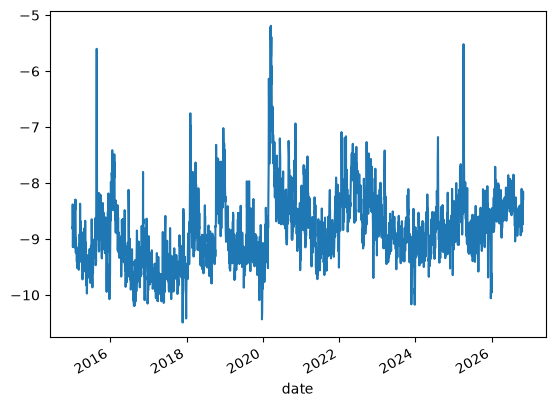

In [42]:
df[df["date"] == "2020-03-16"]["m_day"].nunique()
mkt.plot()

### HAR MODEL with extra features

In [ ]:
base = ["x_day", "x_week", "x_month"]
feature_sets = {
    "base": base,
    "+ m_day": base + ["m_day"],
    "+ m_day + m_week": base + ["m_day", "m_week"],
}

In [43]:
results = {}

In [44]:
base = ["x_day", "x_week", "x_month"]
feature_sets = {
    "base": base,
    "+ m_day": base + ["m_day"],
    "+ m_day + m_week": base + ["m_day", "m_week"],
}

for cutoff in ["2019-01-01", "2021-01-01"]:
    train = df[df["date"] < cutoff]
    test  = df[df["date"] >= cutoff]
    results[("tomorrow = today", cutoff)] = mean_squared_error(test["target"], test["x_day"])

    for name, features in feature_sets.items():
        har = LinearRegression()
        har.fit(train[features], train["target"])
        mse_har = mean_squared_error(test["target"], har.predict(test[features]))
        print(cutoff, name, har.coef_.round(3), round(har.intercept_, 3), mse_har)
        results[("HAR " + name, cutoff)] = mse_har

pd.Series(results).unstack()

2019-01-01 base [0.419 0.252 0.284] -0.411 0.2910214677896579
2019-01-01 + m_day [0.374 0.217 0.317 0.132] 0.366 0.2886728530895942
2019-01-01 + m_day + m_week [ 0.277  0.356  0.304  0.403 -0.349] -0.071 0.28437753110924024
2021-01-01 base [0.418 0.335 0.194] -0.476 0.2820679403199609
2021-01-01 + m_day [0.377 0.304 0.209 0.112] 0.022 0.27874189847104897
2021-01-01 + m_day + m_week [ 0.281  0.43   0.213  0.371 -0.319] -0.213 0.27480815648447193


,2019-01-01,2021-01-01
HAR + m_day,0.288673,0.278742
HAR + m_day + m_week,0.284378,0.274808
HAR base,0.291021,0.282068
tomorrow = today,0.386018,0.381721


### Consistent: each addition helps in both splits, and the error falls by about 2.3% (2019) and 2.6% (2021) in total. A gain that shows up in both cutoffs, with m_week adding more on top of m_day, is the sign we said to look for.
### Modest: about 2.5% is small in absolute terms but real, and it’s about what you’d expect from adding a feature that mostly cleans up an existing signal.

In [45]:
for cutoff in ["2019-01-01", "2021-01-01"]:
    train = df[df["date"] < cutoff]
    test  = df[df["date"] >= cutoff]

    for name, features in feature_sets.items():
        # 1. pandas -> PyTorch tensors, built from THIS feature set's columns
        X_train = torch.tensor(np.array(train[features], dtype=np.float32))
        y_train = torch.tensor(np.array(train["target"], dtype=np.float32)).reshape(-1, 1)
        X_test  = torch.tensor(np.array(test[features],  dtype=np.float32))
        y_test  = torch.tensor(np.array(test["target"],  dtype=np.float32)).reshape(-1, 1)

        losses = []                                   # fresh list for each feature set
        for seed in [0, 1, 2]:
            torch.manual_seed(seed)

            # 2. the model (the input size follows the number of features)
            mlp = nn.Sequential(
                nn.Linear(len(features), 8),
                nn.ReLU(),
                nn.Linear(8, 1)
            )

            # 3. error measure and optimizer
            loss_fn = nn.MSELoss()
            optimizer = torch.optim.Adam(mlp.parameters(), lr=0.05)

            # 4. training loop
            for epoch in range(3000):
                pred = mlp(X_train)
                loss = loss_fn(pred, y_train)
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            # 5. score on the test set
            with torch.no_grad():
                test_loss = loss_fn(mlp(X_test), y_test)
            losses.append(test_loss.item())

        results[("MLP " + name, cutoff)] = np.mean(losses)
        print(cutoff, name, losses)

pd.Series(results).unstack()

2019-01-01 base [0.2910214066505432, 0.29101765155792236, 0.29102185368537903]
2019-01-01 + m_day [0.28863900899887085, 0.2883360683917999, 0.2886010706424713]
2019-01-01 + m_day + m_week [0.2846648395061493, 0.28462448716163635, 0.28483226895332336]
2021-01-01 base [0.2839900255203247, 0.2820681929588318, 0.28206801414489746]
2021-01-01 + m_day [0.27874132990837097, 0.27869853377342224, 0.278718501329422]
2021-01-01 + m_day + m_week [0.27513211965560913, 0.2751714587211609, 0.27531060576438904]


,2019-01-01,2021-01-01
HAR + m_day,0.288673,0.278742
HAR + m_day + m_week,0.284378,0.274808
HAR base,0.291021,0.282068
MLP + m_day,0.288525,0.278719
MLP + m_day + m_week,0.284707,0.275205
MLP base,0.291020,0.282709
tomorrow = today,0.386018,0.381721


### The lever is information, not flexibility. Adding the market features helped both models by about the same amount (about 2.5%), and the nonlinear network gained nothing extra. Even with 5 inputs and 40× more data, the relationship is close to linear in logs.
### This is a finding worth reporting. “On HAR-type inputs, an MLP matches HAR but doesn’t beat it; the gains came from adding the market-wide feature.”

# Part 3 adding downside share and jump share (last test for today)

In [47]:
df = stocks.sort_values(["symbol", "date"]).copy()   # a fresh copy of the raw table

# mask the 6 bad stock-days (set rv5 to missing)
bad_days = [("2023-01-24", "MCD"), ("2023-01-24", "NKE"), ("2023-01-24", "V"),
            ("2023-01-24", "WMT"), ("2023-01-24", "XOM"), ("2016-09-27", "PG")]
for d, s in bad_days:
    df.loc[(df["date"] == d) & (df["symbol"] == s), "rv5"] = np.nan

df["y"] = np.log(df["rv5"])                          # log volatility

In [48]:
mkt = df.groupby("date")["y"].mean()   # one number per date: the average log-volatility of the stocks
mkt_week = mkt.rolling(5).mean()  # the 5-day rolling average of mkt

df["m_day"]  = df["date"].map(mkt)
df["m_week"] = df["date"].map(mkt_week)
df['downside_share'] = df["rsn5"] / df["rv5"]
df["jump_share"] = (df["rv5"] - df["bv5"]).clip(lower=0) / df["rv5"]


In [49]:
df.loc[df["y"].isna(), ["downside_share", "jump_share"]] = np.nan

In [51]:
df['x_week'] = df.groupby('symbol')['y'].transform(lambda s: s.rolling(5).mean())
df['x_day'] = df['y']
df['x_month'] = df.groupby('symbol')['y'].transform(lambda s: s.rolling(22).mean())
df["target"] = df.groupby('symbol')["y"].shift(-1)
df

,date,symbol,asset_type,volume,trades,open_price,close_price,high_price,low_price,pr,...,index,y,m_day,m_week,downside_share,jump_share,x_week,x_day,x_month,target
0,2015-01-02,AAPL,stocks,52510449,286295,111.3973,109.240,111.4700,107.3500,0.000512,...,"DOW30, S&P100",-7.770309,-8.794514,NaN,0.758946,0.137643,NaN,-7.770309,NaN,-8.028547
1,2015-01-05,AAPL,stocks,60727778,316713,108.2914,106.380,108.6500,105.4100,0.000331,...,"DOW30, S&P100",-8.028547,-8.820304,NaN,0.620611,0.000000,NaN,-8.028547,NaN,-7.653719
2,2015-01-06,AAPL,stocks,64865433,362762,106.4644,106.300,107.4200,104.6300,0.000250,...,"DOW30, S&P100",-7.653719,-8.381195,NaN,0.515478,0.000000,NaN,-7.653719,NaN,-8.764940
3,2015-01-07,AAPL,stocks,39052235,220326,107.1898,107.825,108.2000,106.6950,0.000071,...,"DOW30, S&P100",-8.764940,-8.791673,NaN,0.432829,0.000000,NaN,-8.764940,NaN,-8.923221
4,2015-01-08,AAPL,stocks,57390801,302187,109.3600,111.940,112.1500,108.7000,0.000352,...,"DOW30, S&P100",-8.923221,-9.144430,-8.786423,0.345357,0.088223,-8.228147,-8.923221,NaN,-8.206490
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
118995,2026-10-26,XOM,stocks,10658330,157582,181.8600,184.540,184.7615,181.5200,0.000113,...,S&P100,-9.233079,-8.570152,-8.391830,0.348609,0.094863,-8.792040,-9.233079,-9.016872,-9.014519
118996,2026-10-27,XOM,stocks,13890404,176666,183.6300,179.920,184.8900,179.7400,0.000288,...,S&P100,-9.014519,-8.734899,-8.479262,0.702511,0.055472,-8.899991,-9.014519,-8.998224,-8.748838
118997,2026-10-28,XOM,stocks,11674520,169865,180.5850,182.020,183.6500,179.9000,0.000154,...,S&P100,-8.748838,-8.464979,-8.483063,0.491197,0.124531,-8.871302,-8.748838,-9.004007,-8.690082
118998,2026-10-29,XOM,stocks,10791337,141263,183.7650,183.290,184.4000,180.9400,0.000129,...,S&P100,-8.690082,-8.149731,-8.482659,0.560391,0.406538,-8.901751,-8.690082,-8.979611,-7.991036


In [52]:
all_feats = ["x_day", "x_week", "x_month", "m_day", "m_week", "downside_share", "jump_share"]
df = df.dropna(subset=all_feats + ["target"])

In [53]:
len(df)

117982

In [54]:
df[["downside_share", "jump_share"]].describe()

,downside_share,jump_share
count,117982.000000,117982.000000
mean,0.496824,0.105150
std,0.140821,0.122717
min,0.004645,0.000000
25%,0.396839,0.000000
50%,0.499073,0.068399
75%,0.597721,0.164834
max,0.996720,0.985511


In [61]:
with_mkt = base + ["m_day", "m_week"]
feature_sets = {
    "base": base,
    "+ m_day": base + ["m_day"],
    "+ m_day + m_week": with_mkt,
    "+ downside": with_mkt + ["downside_share"],
    "+ downside + jump": with_mkt + ["downside_share", "jump_share"],
    "+ jump": with_mkt + ["jump_share"],
}

In [62]:
results = {}

In [63]:
for cutoff in ["2019-01-01", "2021-01-01"]:
    train = df[df["date"] < cutoff]
    test  = df[df["date"] >= cutoff]
    results[("tomorrow = today", cutoff)] = mean_squared_error(test["target"], test["x_day"])

    for name, features in feature_sets.items():
        har = LinearRegression()
        har.fit(train[features], train["target"])
        mse_har = mean_squared_error(test["target"], har.predict(test[features]))
        print(cutoff, name, har.coef_.round(3), round(har.intercept_, 3), mse_har)
        results[("HAR " + name, cutoff)] = mse_har

pd.Series(results).unstack()

2019-01-01 base [0.419 0.252 0.284] -0.411 0.2910214677896579
2019-01-01 + m_day [0.374 0.217 0.317 0.132] 0.366 0.2886728530895942
2019-01-01 + m_day + m_week [ 0.277  0.356  0.304  0.403 -0.349] -0.071 0.28437753110924024
2019-01-01 + downside [ 0.278  0.355  0.304  0.396 -0.341  0.176] -0.156 0.28482972052938116
2019-01-01 + downside + jump [ 0.289  0.348  0.302  0.384 -0.334  0.168 -0.175] -0.167 0.2836012839251267
2019-01-01 + jump [ 0.289  0.348  0.301  0.39  -0.341 -0.185] -0.086 0.28314112818441683
2021-01-01 base [0.418 0.335 0.194] -0.476 0.2820679403199609
2021-01-01 + m_day [0.377 0.304 0.209 0.112] 0.022 0.27874189847104897
2021-01-01 + m_day + m_week [ 0.281  0.43   0.213  0.371 -0.319] -0.213 0.27480815648447193
2021-01-01 + downside [ 0.281  0.43   0.213  0.368 -0.316  0.069] -0.247 0.27468876065828896
2021-01-01 + downside + jump [ 0.297  0.418  0.211  0.351 -0.304  0.061 -0.256] -0.251 0.27340352218640857
2021-01-01 + jump [ 0.297  0.417  0.211  0.353 -0.306 -0.258] -

,2019-01-01,2021-01-01
HAR + downside,0.284830,0.274689
HAR + downside + jump,0.283601,0.273404
HAR + jump,0.283141,0.273507
HAR + m_day,0.288673,0.278742
HAR + m_day + m_week,0.284378,0.274808
HAR base,0.291021,0.282068
tomorrow = today,0.386018,0.381721


In [64]:
for cutoff in ["2019-01-01", "2021-01-01"]:
    train = df[df["date"] < cutoff]
    test  = df[df["date"] >= cutoff]

    for name, features in feature_sets.items():
        # 1. pandas -> PyTorch tensors, built from THIS feature set's columns
        X_train = torch.tensor(np.array(train[features], dtype=np.float32))
        y_train = torch.tensor(np.array(train["target"], dtype=np.float32)).reshape(-1, 1)
        X_test  = torch.tensor(np.array(test[features],  dtype=np.float32))
        y_test  = torch.tensor(np.array(test["target"],  dtype=np.float32)).reshape(-1, 1)

        losses = []                                   # fresh list for each feature set
        for seed in [0, 1, 2]:
            torch.manual_seed(seed)

            # 2. the model (the input size follows the number of features)
            mlp = nn.Sequential(
                nn.Linear(len(features), 8),
                nn.ReLU(),
                nn.Linear(8, 1)
            )

            # 3. error measure and optimizer
            loss_fn = nn.MSELoss()
            optimizer = torch.optim.Adam(mlp.parameters(), lr=0.05)

            # 4. training loop
            for epoch in range(3000):
                pred = mlp(X_train)
                loss = loss_fn(pred, y_train)
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            # 5. score on the test set
            with torch.no_grad():
                test_loss = loss_fn(mlp(X_test), y_test)
            losses.append(test_loss.item())

        results[("MLP " + name, cutoff)] = np.mean(losses)
        print(cutoff, name, losses)

pd.Series(results).unstack()

2019-01-01 base [0.2910214066505432, 0.29101765155792236, 0.29102185368537903]
2019-01-01 + m_day [0.28863900899887085, 0.2883360683917999, 0.2886010706424713]
2019-01-01 + m_day + m_week [0.2846648395061493, 0.28462448716163635, 0.28483226895332336]
2019-01-01 + downside [0.28529247641563416, 0.2860352396965027, 0.28601697087287903]
2019-01-01 + downside + jump [0.2836536765098572, 0.28379571437835693, 0.2837286591529846]
2019-01-01 + jump [0.2833336889743805, 0.28385764360427856, 0.2837536036968231]
2021-01-01 base [0.2839900255203247, 0.2820681929588318, 0.28206801414489746]
2021-01-01 + m_day [0.27874132990837097, 0.27869853377342224, 0.278718501329422]
2021-01-01 + m_day + m_week [0.27513211965560913, 0.2751714587211609, 0.27531060576438904]
2021-01-01 + downside [0.27508389949798584, 0.2760627865791321, 0.27642545104026794]
2021-01-01 + downside + jump [0.27349990606307983, 0.2736796438694, 0.273494690656662]
2021-01-01 + jump [0.27377259731292725, 0.2746288478374481, 0.274884432

,2019-01-01,2021-01-01
HAR + downside,0.284830,0.274689
HAR + downside + jump,0.283601,0.273404
HAR + jump,0.283141,0.273507
HAR + m_day,0.288673,0.278742
HAR + m_day + m_week,0.284378,0.274808
HAR base,0.291021,0.282068
MLP + downside,0.285782,0.275857
MLP + downside + jump,0.283726,0.273558
MLP + jump,0.283648,0.274429
MLP + m_day,0.288525,0.278719


### Best model: HAR with m_day, m_week and jump_share, at 0.2831 (2019) and 0.2735 (2021), versus 0.2910 and 0.2821 for plain HAR. That’s about 2.7–3.0% better.
### Nonlinearity doesn’t help on these inputs. The gains came from information (market state, jumps).